In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

In [19]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc')
        ds_input = xr.open_mfdataset(f'{base_path}/{experiment}/tot/filtered_decomposition_data_flipped_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})
        F1 = ds_input['F1'].mean('time')
        F1_std = (ds_input['F1'].std('time')/np.sqrt(2*365*50)).rename('F1_std')
        F2 = ds_input['F2'].mean('time')
        F2_std = (ds_input['F2'].std('time')/np.sqrt(2*365*50)).rename('F2_std')
        F3 = ds_input['F3'].mean('time')
        F3_std = (ds_input['F3'].std('time')/np.sqrt(2*365*50)).rename('F3_std')
        ds = xr.merge([F1,F2,F3,F1_std,F2_std,F3_std])
        ds.to_netcdf(f'{base_path}/{experiment}/lin_fluxes_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
        ds_input.close()

else:
    for i,experiment in enumerate(experiments):
        ds_fluxes = xr.open_dataset(f'{base_path}/{experiment}/lin_fluxes_CLIM_1.5x1.5.nc')
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
        ds = xr.merge([ds, ds_fluxes])
        ds['CLIM_transient_flux_std'] = np.sqrt(ds['F1_std']**2 + ds['F2_std']**2 + ds['F3_std']**2)
        ds_clims.append(ds)

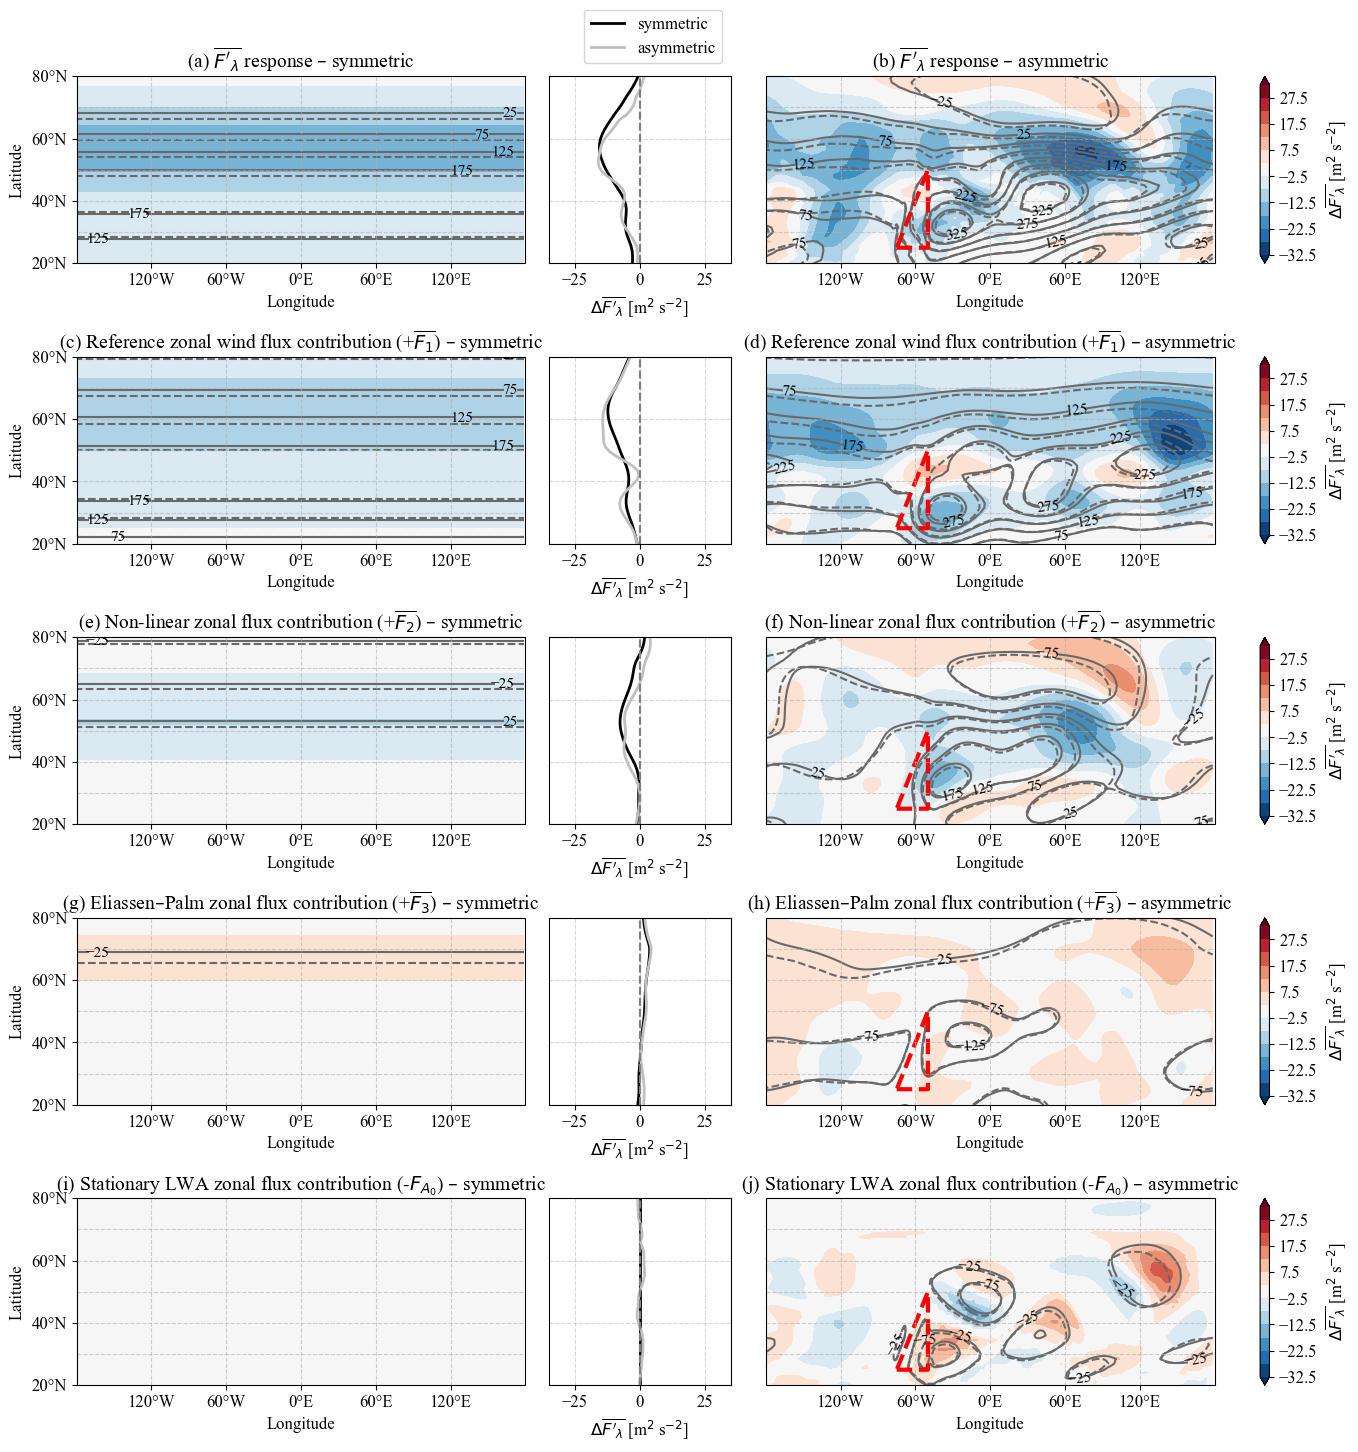

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs

plt.rcParams['font.size'] = 12

# Assumes ds_clims is already defined:
#   ds_clims[0], ds_clims[1] -> symmetric  (baseline, AA)
#   ds_clims[2], ds_clims[3] -> asymmetric (baseline, AA)

# ==================================================
# Settings to check
# ==================================================
# (label, variable, sign) of the flux components. CHECK that the mapping F1/F2/F3 is right.
# F_tot = sum(sign * variable) = F1 + F2 + F3 - FA0 (first row);
# each of the following rows shows sign * variable, i.e. the actual contribution
# of the term to F_tot (so the 5th row is -FA0).
TERMS = [
    (r'Reference zonal wind flux contribution (+$\overline{F_1}$)',                  'F1',  +1),
    (r'Non-linear zonal flux contribution (+$\overline{F_2}$)',                      'F2',  +1),
    (r'Eliassen–Palm zonal flux contribution (+$\overline{F_3}$)',                   'F3',  +1),
    (r'Stationary LWA zonal flux contribution (-$F_{A_0}$)',    'FA0', -1),
]
UNITS = r'm$^2$ s$^{-2}$'     # CHECK units of F1, F2, F3, FA0

LAT_MIN, LAT_MAX = 20, 80
ASPECT = 2.5

# ==================================================
# Helpers
# ==================================================
def broadcast_zonal(field, ref):
    return field.mean('lon').broadcast_like(ref)

def combine(ds, terms):
    """Signed sum of the (variable, sign) terms."""
    return sum(s * ds[v] for v, s in terms)

# ==================================================
# Precompute fields and differences
# ==================================================
# row 0: total F1 + F2 + F3 - FA0; rows 1-4: F1, F2, F3, -FA0
rows = [(r"$\overline{F'_{\lambda}}$ response", [(v, s) for _, v, s in TERMS])] \
     + [(lab, [(v, s)]) for lab, v, s in TERMS]
n_rows = len(rows)          # 5

data = {}   # (i, row) -> dict
for i in range(2):
    zonal = (i == 0)
    ds_a, ds_b = ds_clims[2*i], ds_clims[2*i+1]
    ref = ds_a[TERMS[0][1]]

    for r, (label, terms) in enumerate(rows):
        fa = combine(ds_a, terms)
        fb = combine(ds_b, terms)

        if zonal:
            fa, fb = broadcast_zonal(fa, ref), broadcast_zonal(fb, ref)

        diff = fb - fa
        data[(i, r)] = dict(a=fa, b=fb, diff=diff, xsec=diff.mean('lon').values)

# per-row levels / limits shared by the symmetric and asymmetric columns
levels_field = np.arange(-225, 1300, 50)
levels_diff  = np.arange(-32.5, 33, 5)
xlims        = 35

# ==================================================
# Figure layout
# ==================================================
fig = plt.figure(figsize=(20, 17))
gs = gridspec.GridSpec(
    nrows=n_rows, ncols=5,
    width_ratios=[6.0, 0.25, 1.2, 0.01, 6.0],
    hspace=0.5, wspace=-0.3
)

titles  = ['symmetric', 'asymmetric']
letters = [f'({chr(97 + k)})' for k in range(2 * n_rows)]   # (a)...(j)
colors  = ['k', 'silver']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()
ax_xsec = []

# ==================================================
# Plot
# ==================================================
for i in range(2):
    XSEC_COL = 2
    MAP_COL  = 0 if i == 0 else 4
    ds_a = ds_clims[2*i]
    lat  = ds_a.lat.values

    for r, (label, terms) in enumerate(rows):
        d = data[(i, r)]

        if i == 0:
            ax_xsec.append(fig.add_subplot(gs[r, XSEC_COL]))
        ax_map = fig.add_subplot(gs[r, MAP_COL], projection=proj, sharey=ax_xsec[r])

        ax_map.set_title(f'{letters[2*r + i]} {label} – {titles[i]}')

        # fields: baseline solid, AA dashed
        c1 = ax_map.contour(ds_a.lon, ds_a.lat, d['a'], levels=levels_field,
                            colors='dimgray', linestyles='solid')
        ax_map.contour(ds_a.lon, ds_a.lat, d['b'], levels=levels_field,
                       colors='dimgray', linestyles='dashed')
        ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

        # difference (shading)
        sh = ax_map.contourf(ds_a.lon, ds_a.lat, d['diff'],
                             levels=levels_diff, cmap='RdBu_r', extend='both')

        if i > 0:
            fig.colorbar(sh, ax=ax_map, label=r"$\Delta \overline{F'_{\lambda}}$ " + f"[{UNITS}]")
            ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

        ax_map.set_extent([ds_a.lon.min(), ds_a.lon.max(), LAT_MIN, LAT_MAX])
        ax_map.set_aspect(ASPECT)
        ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
        ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
        ax_map.set_xlabel('Longitude')

        if i == 0:
            ax_map.set_yticks([20, 40, 60, 80])
            ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
            ax_map.set_ylabel('Latitude')
        else:
            plt.setp(ax_map.get_yticklabels(), visible=False)

        ax_map.gridlines(draw_labels=False, linestyle='--', alpha=0.6)

        # zonal mean (middle column)
        ax = ax_xsec[r]
        ax.plot(d['xsec'], lat, color=colors[i], lw=2, label=titles[i])
        ax.axvline(0, color='gray', ls='--')
        ax.set_xlim(-xlims, xlims)
        ax.set_ylim(LAT_MIN, LAT_MAX)
        ax.set_xlabel(r"$\Delta \overline{F'_{\lambda}}$ " + f"[{UNITS}]")
        ax.grid(True, ls='--', alpha=0.5)
        ax.tick_params(axis='y', length=0)
        plt.setp(ax.get_yticklabels(), visible=False)

        if r == 0 and i == 1:
            ax.legend(loc='upper right', bbox_to_anchor=(1.0, 1.4))

# --------------------------------------------------
plt.savefig('PLOTS/Figure_7.png', dpi=300, bbox_inches='tight')
plt.show()